In [1]:
import matplotlib.pyplot as plt
import os
import numpy as np


def read_file(file_path):
    data = []
    with open(file_path, 'r') as file:
        next(file)  # ignore the first line
        for line in file:
            parts = line.split()
            row = list(map(float, parts))
            data.append(row)
    return data


def get_greedy_BPP(x_values, y_values):
    # Sort data by y_values while keeping x_values in corresponding order
    sorted_pairs = sorted(zip(y_values, x_values, range(len(y_values))), key=lambda x: x[0], reverse=True)
    sorted_y_values, sorted_x_values, sorted_index = zip(*sorted_pairs)  # Unzip pairs into separate lists

    best_y = sorted_y_values[0]
    best_x = sorted_x_values[0]
    print("Best accuracy: {y:.8f} at epoch: {index:.0f} with BPP: {x:.8f}".format(y=best_y, index=sorted_index[0]+1, x=best_x))
    
    new_y = []
    new_x = []
    new_index = []
    for index, y_value in enumerate(sorted_y_values):
        if sorted_x_values[index] <= best_x and y_value <= best_y:
            best_x = sorted_x_values[index]
            best_y = y_value
            new_y.append(y_value)
            new_x.append(sorted_x_values[index])
            new_index.append(sorted_index[index])
    
    return new_x, new_y, new_index


def get_greedy_Entropy(x_values, y_values):
    # Sort data by y_values while keeping x_values in corresponding order
    sorted_pairs = sorted(zip(y_values, x_values, range(len(y_values))), key=lambda x: x[0], reverse=True)
    sorted_y_values, sorted_x_values, sorted_index = zip(*sorted_pairs)  # Unzip pairs into separate lists

    best_y = sorted_y_values[0]
    best_x = sorted_x_values[0]
    print("Best accuracy: {y:.8f} at epoch: {index:.0f} with Entropy: {x:.8f}".format(y=best_y, index=sorted_index[0]+1, x=best_x))
    
    new_y = []
    new_x = []
    new_index = []
    for index, y_value in enumerate(sorted_y_values):
        if sorted_x_values[index] <= best_x and y_value <= best_y:
            best_x = sorted_x_values[index]
            best_y = y_value
            new_y.append(y_value)
            new_x.append(sorted_x_values[index])
            new_index.append(sorted_index[index])
    
    return new_x, new_y, new_index


def plot_data_bpp(file_path, marker, label, color, greedy=True):
    data = read_file(file_path)
    y_values = [row[2] for row in data] # test acc
    # x_values = [269.63494 / (row[7] + row[8] + row[9] + row[10]) for row in data] # CR
    x_values = [(row[6]) for row in data] # test bpp
    
    if len(x_values) > 100:
        y_values = y_values[:100]
        x_values = x_values[:100]
    # x_values = [row[4] for row in data] # test loss

    if greedy:
        new_x_values, new_y_values, new_index = get_greedy_BPP(x_values, y_values)
        plt.plot(x_values, y_values, marker=marker, color=color, alpha=0.2, linestyle="")
        plt.plot(new_x_values, new_y_values, marker=marker, label=label, color=color, alpha=1)
        # for i, (x, y) in enumerate(zip(new_x_values, new_y_values)):
        #     plt.annotate(str(new_index[i]+1), (x, y), textcoords="offset points", xytext=(0,10), ha='center')
        return new_index[0]+1
    else:
        # plt.plot(x_values, y_values, marker=marker, label=label, color=color, alpha=0.9, linestyle="")
        plt.plot(x_values, y_values, marker=marker, label=label, color=color, alpha=0.9)
        for i, (x, y) in enumerate(zip(x_values, y_values)):
            plt.annotate(str(i+1), (x, y), textcoords="offset points", xytext=(0,10), ha='center')
        return -1


def plot_data_entropy(file_path, marker, label, color, greedy=True):
    data = read_file(file_path)
    y_values = [row[2] for row in data] # test acc
    x_values = [(row[7] + row[8] + row[9] + row[10]) for row in data] # entropy
    # x_values = [24 / (row[6]) for row in data] # bpp
    
    if len(x_values) > 100:
        y_values = y_values[:100]
        x_values = x_values[:100]
    # x_values = [row[4] for row in data] # test loss

    if greedy:
        new_x_values, new_y_values, new_index = get_greedy_Entropy(x_values, y_values)
        plt.plot(x_values, y_values, marker=marker, color=color, alpha=0.2, linestyle="")
        plt.plot(new_x_values, new_y_values, marker=marker, label=label, color=color, alpha=1)
        for i, (x, y) in enumerate(zip(new_x_values, new_y_values)):
            plt.annotate(str(new_index[i]+1), (x, y), textcoords="offset points", xytext=(0,10), ha='center')
        return new_index[0]+1
    else:
        # plt.plot(x_values, y_values, marker=marker, label=label, color=color, alpha=0.9, linestyle="")
        plt.plot(x_values, y_values, marker=marker, label=label, color=color, alpha=0.9)
        for i, (x, y) in enumerate(zip(x_values, y_values)):
            plt.annotate(str(i+1), (x, y), textcoords="offset points", xytext=(0,10), ha='center')
        return -1


def plot_data_HDQ(base_path='./save/imagenet/resnet18', lower=1, upper=100):
    HDQ_file = os.path.join(base_path,"HDQ.txt")
    data = read_file(HDQ_file)
    # plot baseline for HDQ
    QF_ls = [int(row[0]) for row in data]
    HDQ_y = [row[1] for row in data]
    HDQ_x = [row[2] for row in data]
    
    sorted_lists = [(qf, y, x) for qf, y, x in sorted(zip(QF_ls, HDQ_y, HDQ_x)) if lower <= qf <= upper]

    QF_ls, HDQ_y, HDQ_x = map(list, zip(*sorted_lists))
    
    plt.plot(HDQ_x, HDQ_y, marker="x", label="HDQ", color='k')
    for i, (x, y) in enumerate(zip(HDQ_x, HDQ_y)):
        plt.annotate(str(QF_ls[i]), (x, y), textcoords="offset points", xytext=(5,-12), ha='center')

# Basic settings

In [2]:
color_list = ['r','g','b','m','y','#cf717f','#1f7f7f','#e377c2','#caada2','#ddd7c2']
marker_list = ['o','^','.','v','>','v','|','_',',','+','x']
# base_path = './save/CUB200/resnet18'
base_path = './save/imagenet/resnet18'

file_name_0 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(0.01, 100.0, 0.1, 0.1, 40)
file_name_1 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(0.01, 100.0, 0.0, 0.0, 20)
file_name_2 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(0.01, 100.0, 0.0, 0.0, 30)
file_name_3 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(0.01, 100.0, 0.0, 0.0, 40)
file_name_4 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(0.01, 100.0, 0.0, 0.0, 50)
file_name_5 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(0.01, 100.0, 0.0, 0.0, 60)
file_name_6 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(0.01, 100.0, 0.0, 0.0, 70)
file_name_7 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(0.01, 100.0, 0.0001, 0.0001, 10)
file_name_8 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(0.01, 100.0, 0.0005, 0.0005, 10)
file_name_9 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(0.01, 100.0, 0.0001, 0.0001, 100)

# file_name_1 = "JPEG_lr_{}_alpha_{}_weight_{}_{}".format(0.01, 100.0, 0.001, 0.001)
# file_name_2 = "JPEG_lr_{}_alpha_{}_weight_{}_{}".format(0.01, 100.0, 10.0, 10.0)
# file_name_3 = "JPEG_lr_{}_alpha_{}_weight_{}_{}".format(0.01, 100.0, 50.0, 50.0)
# file_name_4 = "JPEG_lr_{}_alpha_{}_weight_{}_{}".format(0.01, 100.0, 1.0, 1.0)
# file_name_5 = "JPEG_lr_{}_alpha_{}_weight_{}_{}".format(0.025, 10.0, 0.005, 0.005)
# file_name_6 = "JPEG_lr_{}_alpha_{}_weight_{}_{}".format(0.005, 100.0, 0.15, 0.15)
# file_name_7 = "JPEG_lr_{}_alpha_{}_weight_{}_{}".format(0.005, 100.0, 0.175, 0.175)
# file_name_8 = "JPEG_lr_{}_alpha_{}_weight_{}_{}".format(0.005, 100.0, 0.2, 0.2)
# file_name_9 = "JPEG_lr_{}_alpha_{}_weight_{}_{}".format(0.005, 100.0, 0.225, 0.225)

# file_name_1 = "JPEG_lr_{}_weight_{}_{}_hardness_{}".format(0.01, 5.0, 5.0, 50.0)
# file_name_2 = "JPEG_lr_{}_weight_{}_{}_hardness_{}".format(0.1, 1.0, 1.0, 20.0)
# file_name_3 = "JPEG_lr_{}_weight_{}_{}_hardness_{}".format(0.1, 1.0, 1.0, 3.0)
# file_name_4 = "JPEG_lr_{}_weight_{}_{}_hardness_{}".format(0.1, 2.0, 2.0, 20.0)
# file_name_5 = "JPEG_lr_{}_weight_{}_{}_hardness_{}".format(0.2, 2.0, 2.0, 20.0)
# file_name_6 = "JPEG_lr_{}_weight_{}_{}_hardness_{}".format(0.5, 2.0, 2.0, 20.0)
# file_name_7 = "JPEG_lr_{}_weight_{}_{}_hardness_{}".format(1.0, 2.0, 2.0, 20.0)
# file_name_8 = "JPEG_lr_{}_weight_{}_{}_hardness_{}".format(2.0, 2.0, 2.0, 20.0)
# file_name_9 = "JPEG_lr_{}_weight_{}_{}_hardness_{}".format(5.0, 2.0, 2.0, 20.0)

# Greedy across all experiments

8
8


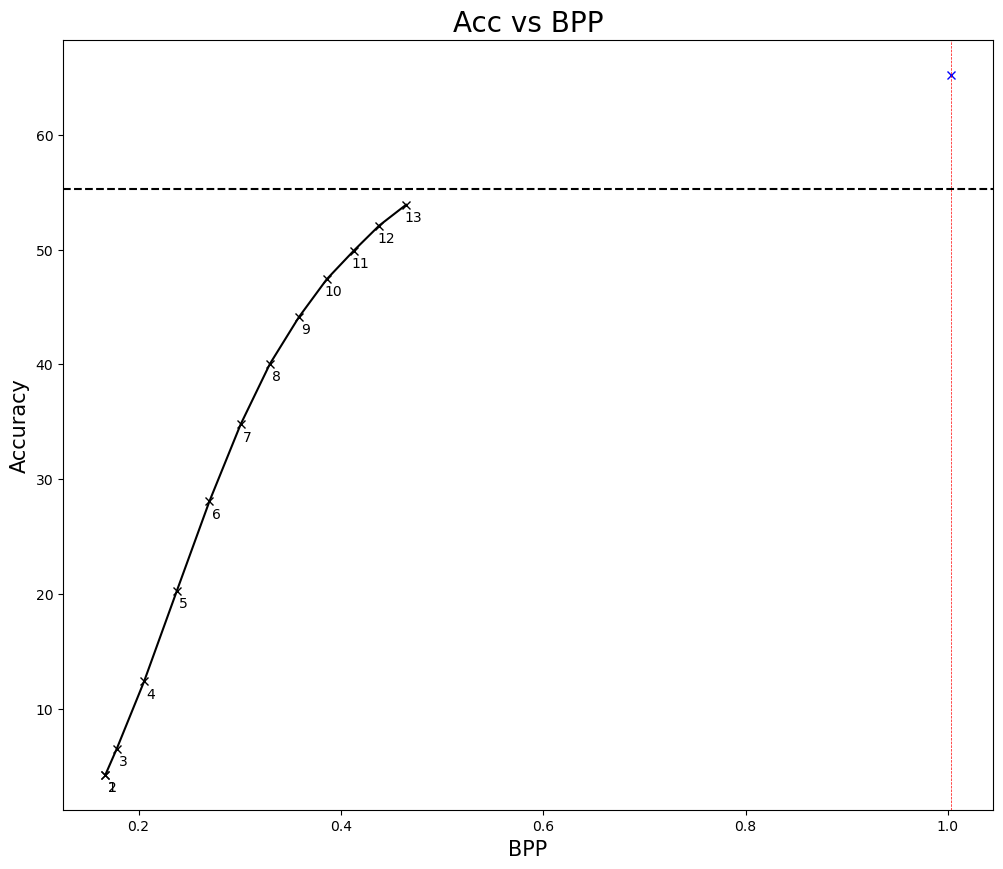

In [14]:
def load_all_log_files(directory):
    all_data = []
    labels = []
    count = 0
    for dir_name in os.listdir(directory):
        dir_path = os.path.join(base_path, dir_name)
        if os.path.isdir(dir_path):
            log_file_path = os.path.join(dir_path, "trial_1/logs.txt")
            if os.path.exists(log_file_path):
                count += 1
                data = read_file(log_file_path)
                all_data.extend(data)
                labels.extend([dir_name]*len(data))
    return all_data, labels


def get_greedy(x_values, y_values, labels):
    # Sort data by y_values while keeping x_values in corresponding order
    sorted_pairs = sorted(zip(y_values, x_values, labels), key=lambda x: x[0], reverse=True)
    sorted_y_values, sorted_x_values, sorted_labels = zip(*sorted_pairs)  # Unzip pairs into separate lists

    best_y = sorted_y_values[0]
    best_x = sorted_x_values[0]
    used_labels = []
    
    new_y = []
    new_x = []
    new_labels = []
    for index, y_value in enumerate(sorted_y_values):
        if sorted_x_values[index] <= best_x and y_value <= best_y and sorted_labels[index] not in used_labels:
            best_x = sorted_x_values[index]
            best_y = y_value
            new_y.append(y_value)
            new_x.append(sorted_x_values[index])
            new_labels.append(sorted_labels[index])
            used_labels.append(sorted_labels[index])
            
    return new_x, new_y, new_labels


plt.figure(figsize=(12, 10))

data, labels = load_all_log_files(base_path)
print("len(data):", len(data))
print("len(labels)", len(labels))
test_acc = [row[2] for row in data]
test_bpp = [(row[6]) for row in data]

new_x_values, new_y_values, new_labels = get_greedy(test_bpp, test_acc, labels)
plt.plot(new_x_values, new_y_values, marker='x', color='b', alpha=1)
# plt.plot(test_bpp, test_acc, marker='x', color='b', alpha=0.1, linestyle="")

# for i, (x, y) in enumerate(zip(new_x_values, new_y_values)):
#     plt.annotate(str(new_labels[i]), (x, y), textcoords="offset points", xytext=(0,10), ha='center')
for x in new_x_values:
    plt.axvline(x=x, color='red', linestyle='--', linewidth=0.5)
# for y in new_y_values:
#     plt.axhline(y=y, color='red', linestyle='--', linewidth=0.5)

# plot baseline for underlying model
plot_data_HDQ(base_path, 1, 90)
plt.axhline(y=55.28, color='black', linestyle='--')
plt.xlabel('BPP', fontsize=15)
plt.ylabel('Accuracy', fontsize=15)
plt.title('Acc vs BPP', fontsize=20) 
# plt.legend(loc="lower right")
# plt.grid(True)
plt.show()

# Plot Acc vs BPP

Best accuracy: 65.23400000 at epoch: 1 with BPP: 1.00280086


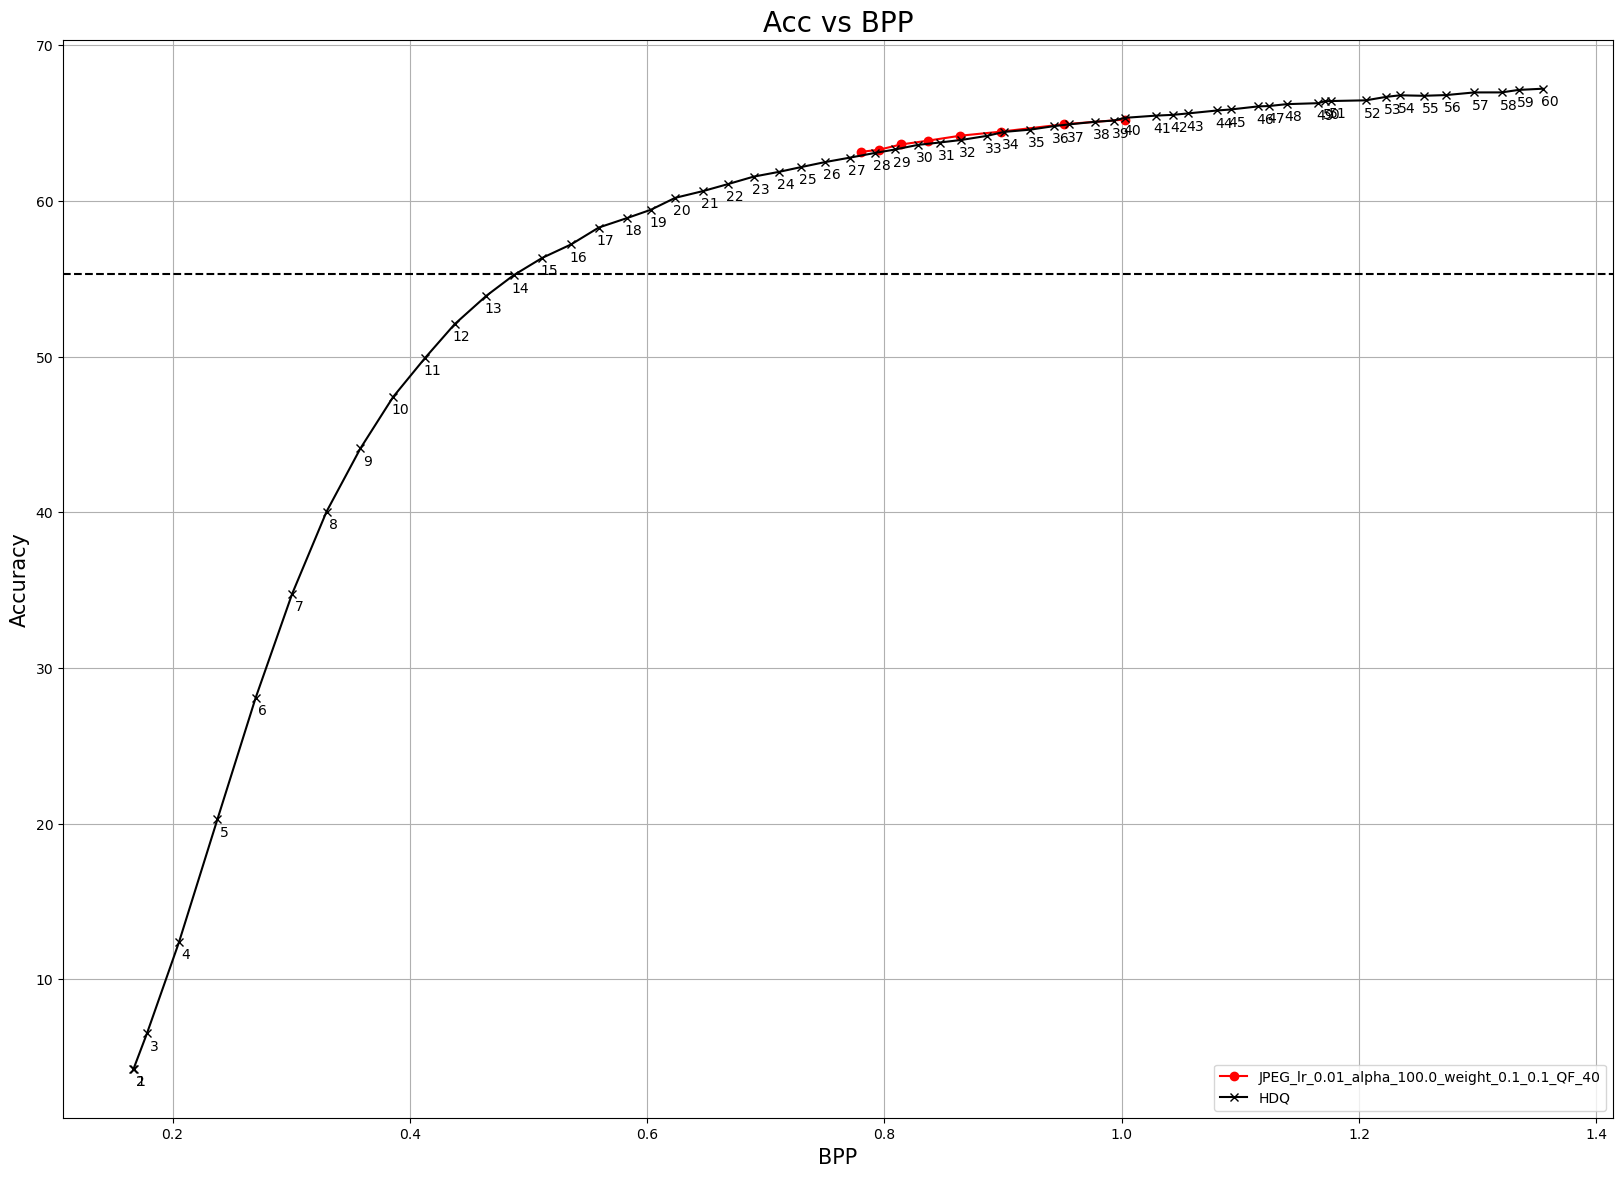

In [5]:
plt.figure(figsize=(20, 14))

best_epoch_0 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_0), "trial_1/logs.txt"), marker_list[0], file_name_0, color=color_list[0], greedy=True)
# best_epoch_1 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_1), "trial_1/logs.txt"), marker_list[1], file_name_1, color=color_list[1], greedy=True)
# best_epoch_2 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_2), "trial_1/logs.txt"), marker_list[2], file_name_2, color=color_list[2], greedy=True)
# best_epoch_3 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_3), "trial_1/logs.txt"), marker_list[3], file_name_3, color=color_list[3], greedy=True)
# best_epoch_4 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_4), "trial_1/logs.txt"), marker_list[4], file_name_4, color=color_list[4], greedy=True)
# best_epoch_5 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_5), "trial_1/logs.txt"), marker_list[5], file_name_5, color=color_list[5], greedy=True)
# best_epoch_6 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_6), "trial_1/logs.txt"), marker_list[6], file_name_6, color=color_list[6], greedy=True)
# best_epoch_7 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_7), "trial_1/logs.txt"), marker_list[7], file_name_7, color=color_list[7], greedy=True)
# best_epoch_8 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_8), "trial_1/logs.txt"), marker_list[8], file_name_8, color=color_list[8], greedy=True)
# best_epoch_9 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_9), "trial_1/logs.txt"), marker_list[9], file_name_9, color=color_list[9], greedy=True)

# plot baseline for underlying model
plot_data_HDQ(base_path, 25, 60)
plt.axhline(y=55.28, color='black', linestyle='--')
plt.xlabel('BPP', fontsize=15)
plt.ylabel('Accuracy', fontsize=15)
plt.title('Acc vs BPP', fontsize=20)
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# Plot Train and Test acc/loss

weight: 0.1
len of data: 8


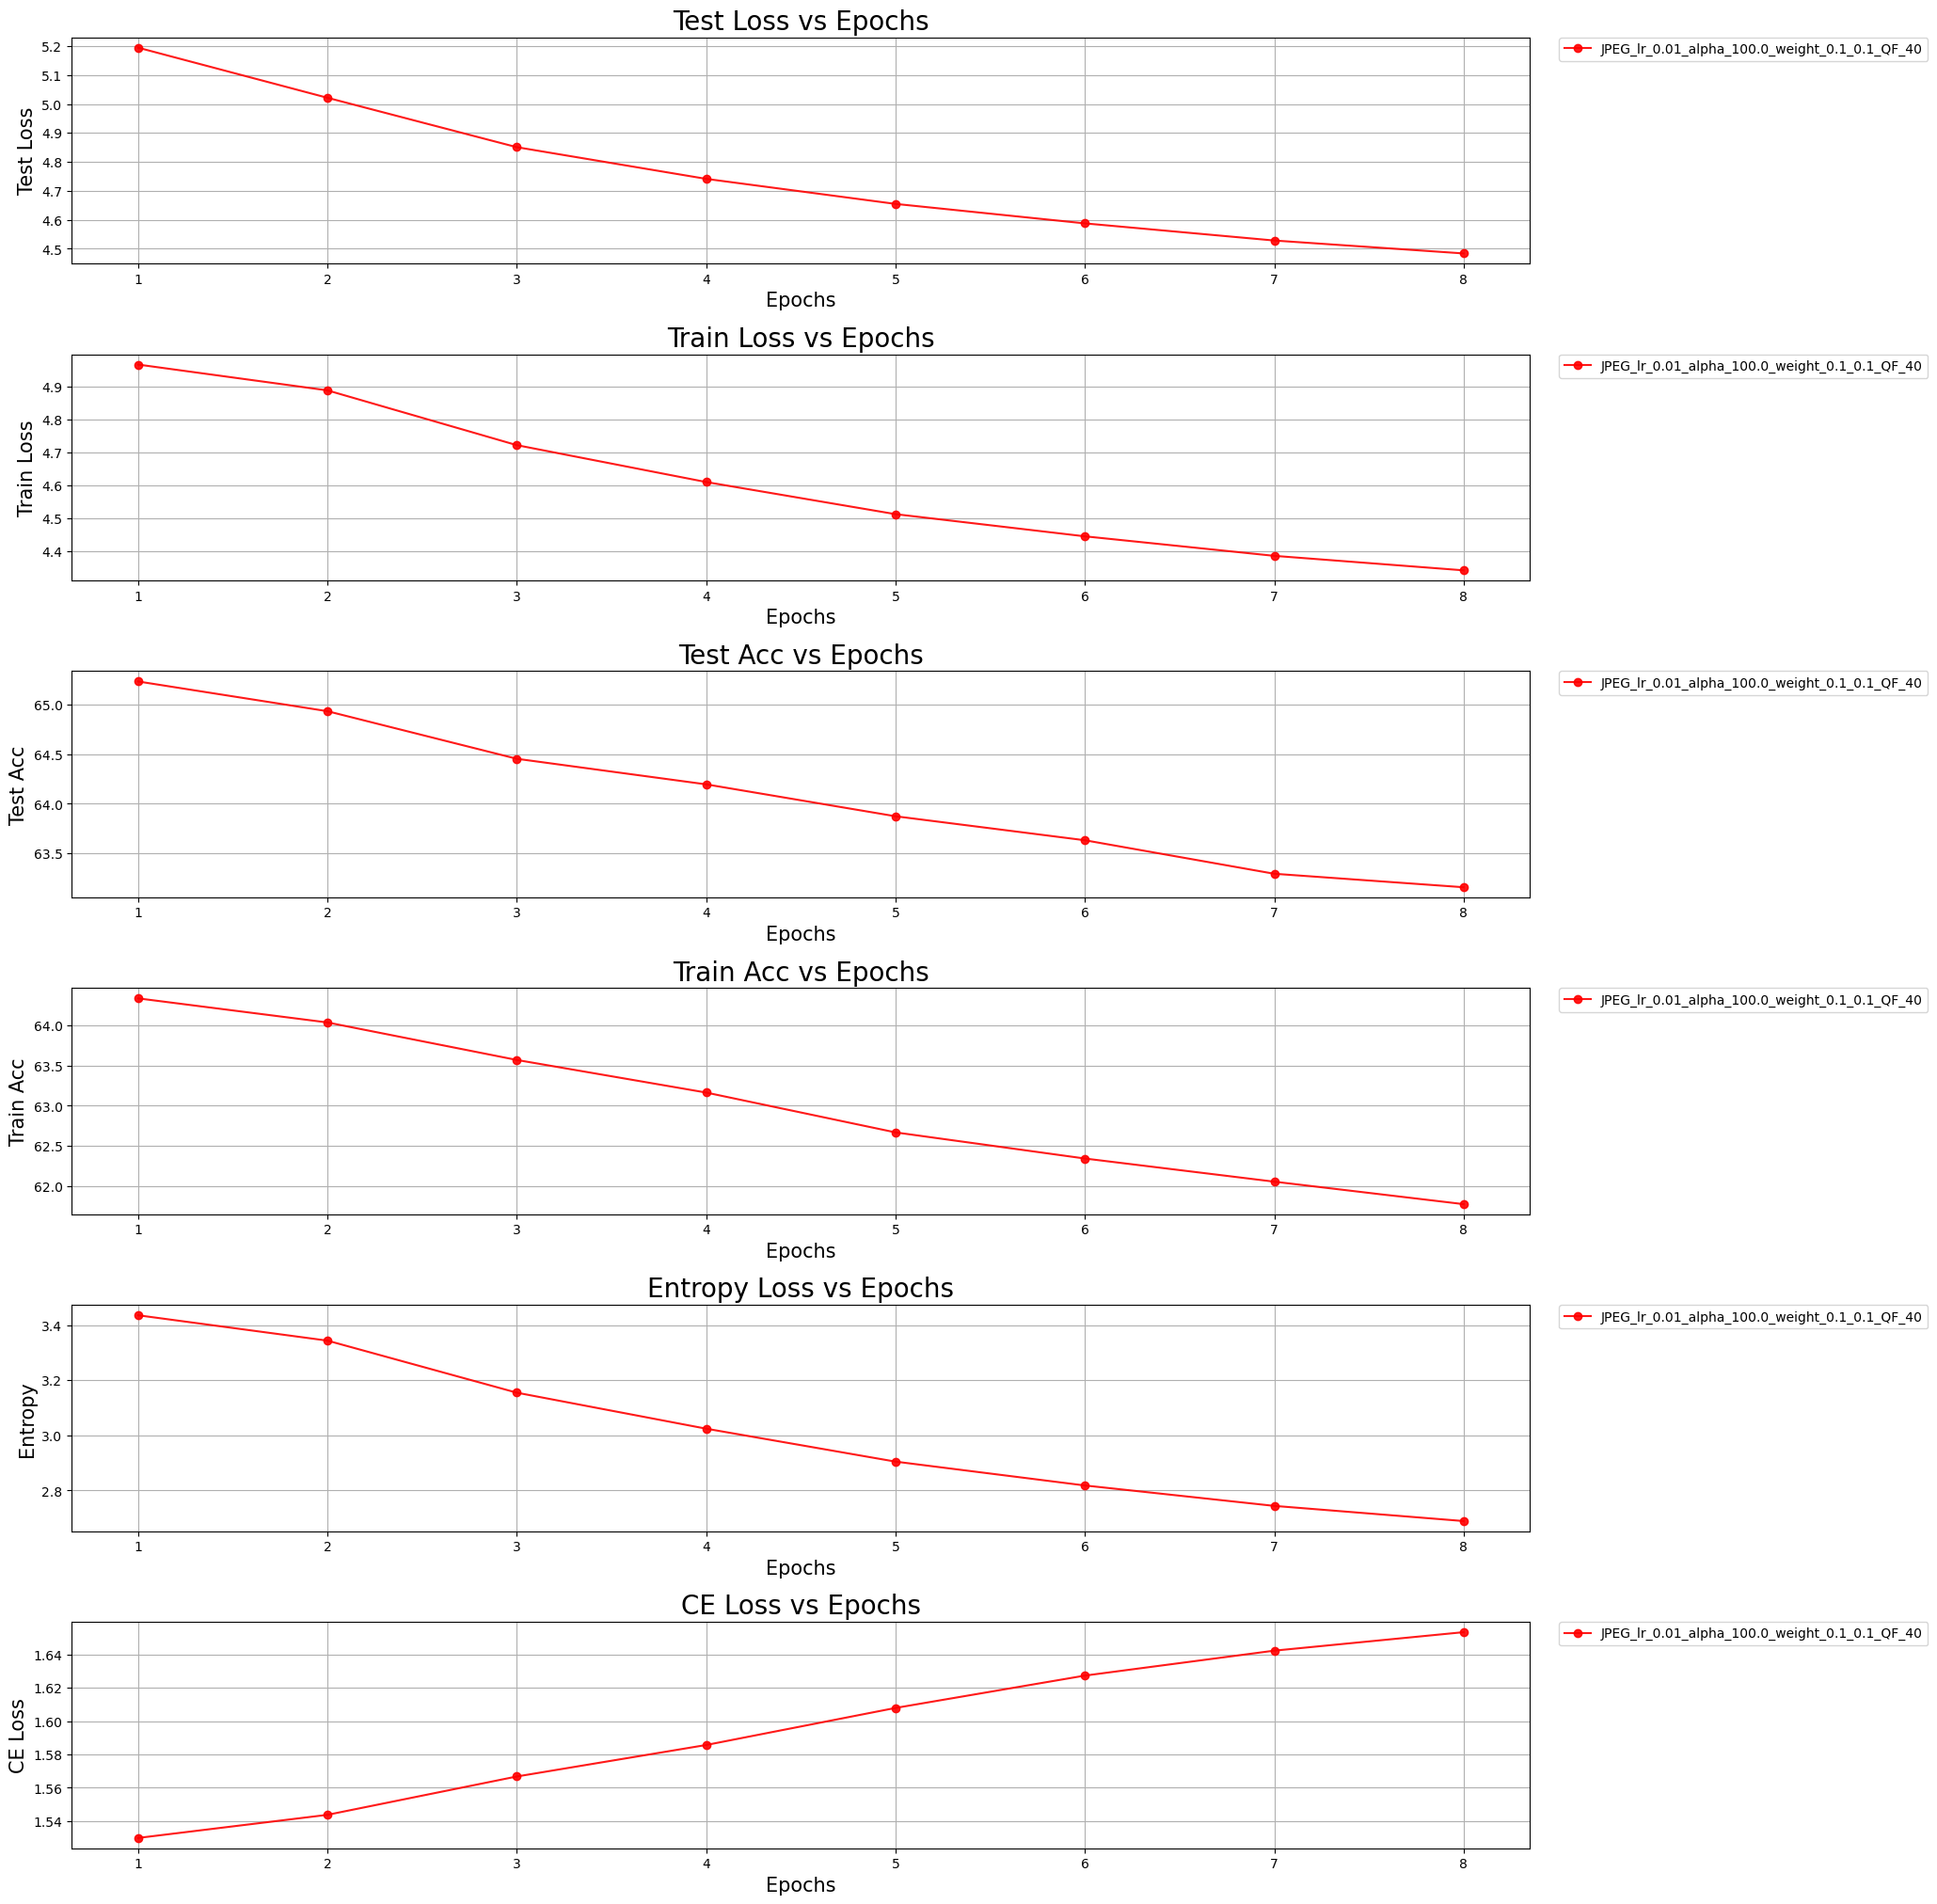

In [12]:
import json
import argparse

def plot_data_acc_loss(file_path, trial, marker, label, color):
    opt_json_filepath = os.path.join(base_path,label,'trial_{}/opt.json'.format(trial))
    with open(opt_json_filepath, 'r') as f:
        data = json.load(f)
    opt = argparse.Namespace(**data)
    
    weight = opt.weight_lum
    print("weight:", weight)
    data = read_file(file_path)
    print("len of data:", len(data))
    test_acc = [row[2] for row in data]
    train_acc = [row[3] for row in data]
    test_loss = [row[4] for row in data]
    train_loss = [row[5] for row in data]
    entropy = [weight*(row[11] + row[12] + row[13] + row[14]) for row in data]
    CEloss = [(row[5] - weight* (row[11] + row[12] + row[13] + row[14])) for row in data]
    # bpp = [row[6] for row in data]
    
    x_epoch = range(1,len(test_loss)+1)
    ax1.plot(x_epoch, test_loss, marker=marker, label=label, color=color, alpha=0.9)
    ax2.plot(x_epoch, train_loss, marker=marker, label=label, color=color, alpha=0.9)
    ax3.plot(x_epoch, test_acc, marker=marker, label=label, color=color, alpha=0.9)
    ax4.plot(x_epoch, train_acc, marker=marker, label=label, color=color, alpha=0.9)
    ax5.plot(x_epoch, entropy, marker=marker, label=label, color=color, alpha=0.9)
    ax6.plot(x_epoch, CEloss, marker=marker, label=label, color=color, alpha=0.9)

fig, (ax1, ax2, ax3, ax4, ax5, ax6) = plt.subplots(6, 1, figsize=(20, 25))

plot_data_acc_loss(os.path.join(os.path.join(base_path, file_name_0), "trial_1/logs.txt"), 1, marker_list[0], file_name_0, color=color_list[0])
# plot_data_acc_loss(os.path.join(os.path.join(base_path, file_name_1), "trial_1/logs.txt"), 1, marker_list[1], file_name_1, color=color_list[0])
# plot_data_acc_loss(os.path.join(os.path.join(base_path, file_name_2), "trial_1/logs.txt"), 1, marker_list[2], file_name_2, color=color_list[1])
# plot_data_acc_loss(os.path.join(os.path.join(base_path, file_name_3), "trial_1/logs.txt"), 1, marker_list[3], file_name_3, color=color_list[2])
# plot_data_acc_loss(os.path.join(os.path.join(base_path, file_name_4), "trial_1/logs.txt"), 1, marker_list[4], file_name_4, color=color_list[3])
# plot_data_acc_loss(os.path.join(os.path.join(base_path, file_name_5), "trial_1/logs.txt"), 1, marker_list[5], file_name_5, color=color_list[4])
# plot_data_acc_loss(os.path.join(os.path.join(base_path, file_name_6), "trial_1/logs.txt"), 1, marker_list[6], file_name_6, color=color_list[5])
# plot_data_acc_loss(os.path.join(os.path.join(base_path, file_name_7), "trial_1/logs.txt"), 1, marker_list[7], file_name_7, color=color_list[6])
# plot_data_acc_loss(os.path.join(os.path.join(base_path, file_name_8), "trial_1/logs.txt"), 1, marker_list[8], file_name_8, color=color_list[7])
# plot_data_acc_loss(os.path.join(os.path.join(base_path, file_name_9), "trial_1/logs.txt"), 1, marker_list[9], file_name_9, color=color_list[8])

axes = [ax1, ax2, ax3, ax4, ax5, ax6]
titles = ['Test Loss vs Epochs', 'Train Loss vs Epochs', 'Test Acc vs Epochs', 'Train Acc vs Epochs', 'Entropy Loss vs Epochs', 'CE Loss vs Epochs']
y_labels = ['Test Loss', 'Train Loss', 'Test Acc', 'Train Acc', 'Entropy', 'CE Loss']

for ax, title, y_label in zip(axes, titles, y_labels):
    ax.set_xlabel('Epochs', fontsize=15)
    ax.set_ylabel(y_label, fontsize=15)
    ax.set_title(title, fontsize=20)
    ax.grid(True)
    ax.legend(bbox_to_anchor=(1.02, 1.0), loc=2, borderaxespad=0)

plt.subplots_adjust(hspace=0.4)
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: './save/CUB200/resnet18/JPEG_lr_0.01_alpha_100.0_weight_0.0_0.0_QF_40/trial_4/train_logs.txt'

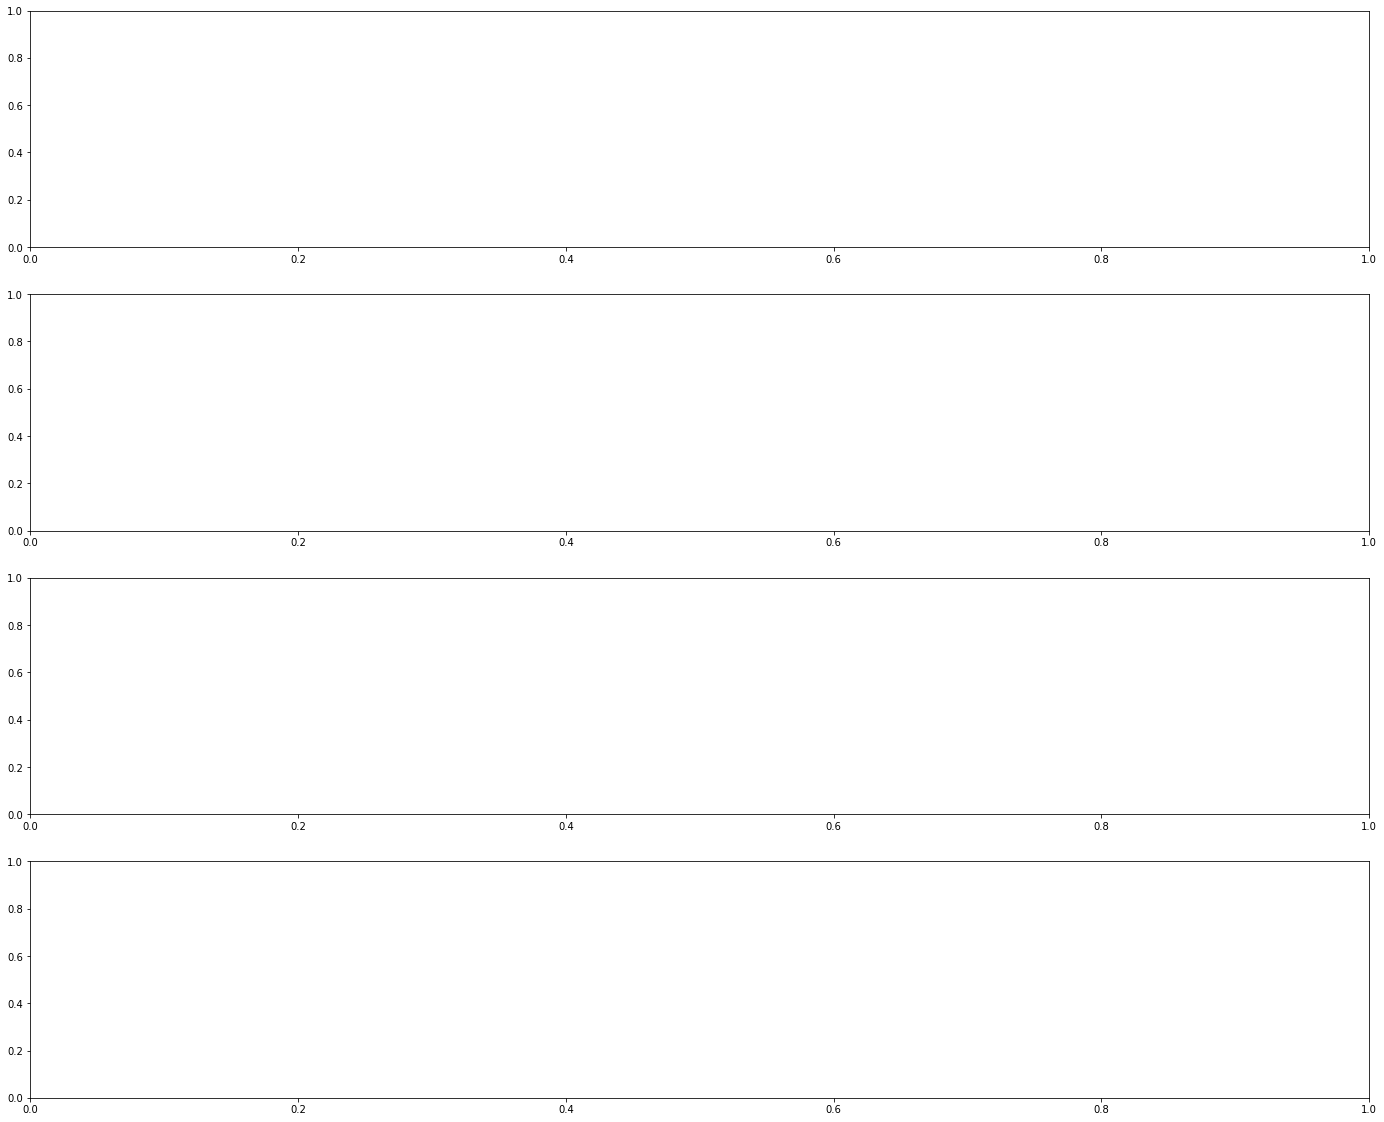

In [12]:
def plot_minibatch_data_acc_loss(file_path, marker, label, color):
    train_data = read_file(os.path.join(file_path, "trial_4/train_logs.txt"))
    test_data = read_file(os.path.join(file_path, "trial_4/val_logs.txt"))
    
    train_loss = [row[1] for row in train_data]
    test_loss = [row[1] for row in test_data]
    train_acc = [row[0] for row in train_data]
    test_acc = [row[0] for row in test_data]
    
    train_epoch = range(1,188+1)
    test_epoch = range(1,363+1)
    
    colors = ['r','g','b','m','y','#cf717f','#1f7f7f','#e377c2','#aaa7c2','#ddd7c2']
    
    # Plot with changing colors every 100 points
    for ax, data in [(ax1, train_loss), (ax3, train_acc)]:
        for i in range(0, len(data), 188):
            end = min(i + 188, len(data))
            color = colors[(i // 188) % len(colors)]
            ax.plot(train_epoch, data[i:end], marker=marker, color=color, label=f'{label} epoch {end//188}', alpha=0.5)
    
    for ax, data in [(ax2, test_loss), (ax4, test_acc)]:
        for i in range(0, len(data), 363):
            end = min(i + 363, len(data))
            color = colors[(i // 363) % len(colors)]
            ax.plot(test_epoch, data[i:end], marker=marker, color=color, label=f'{label} epoch {end//363}', alpha=0.5)
    
    # ax1.plot(train_epoch, train_loss, marker=marker, label=label, color=color, alpha=0.9)
    # ax2.plot(test_epoch, test_loss, marker=marker, label=label, color=color, alpha=0.9)
    # ax3.plot(train_epoch, train_acc, marker=marker, label=label, color=color, alpha=0.9)
    # ax4.plot(test_epoch, test_acc, marker=marker, label=label, color=color, alpha=0.9)


fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(24, 20))

plot_minibatch_data_acc_loss(os.path.join(base_path, file_name_3), marker_list[0], file_name_3, color=color_list[3])

ax1.set_xlabel('Epochs', fontsize=15)
ax1.set_ylabel('Train Loss', fontsize=15)
ax1.set_title('Train Loss vs Epochs', fontsize=20)
ax1.grid(True)
ax1.legend(bbox_to_anchor=(1.02, 1.0), loc=2, borderaxespad=0)

ax2.set_xlabel('Epochs', fontsize=15)
ax2.set_ylabel('Test Loss', fontsize=15)
ax2.set_title('Test Loss vs Epochs', fontsize=20)
ax2.grid(True)
ax2.legend(bbox_to_anchor=(1.02, 1.0), loc=2, borderaxespad=0)

ax3.set_xlabel('Epochs', fontsize=15)
ax3.set_ylabel('Train Acc', fontsize=15)
ax3.set_title('Train Acc vs Epochs', fontsize=20)
ax3.grid(True)
ax3.legend(bbox_to_anchor=(1.02, 1.0), loc=2, borderaxespad=0)

ax4.set_xlabel('Epochs', fontsize=15)
ax4.set_ylabel('Test Acc', fontsize=15)
ax4.set_title('Test Acc vs Epochs', fontsize=20)
ax4.grid(True)
ax4.legend(bbox_to_anchor=(1.02, 1.0), loc=2, borderaxespad=0)

plt.subplots_adjust(hspace=0.4)
plt.show()

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import os


def zigzag(matrix):
    zigzag = np.array([[0, 1, 5, 6, 14, 15, 27, 28],
                        [2, 4, 7, 13, 16, 26, 29, 42],
                        [3, 8, 12, 17, 25, 30, 41, 43],
                        [9, 11, 18, 24, 31, 40, 44, 53],
                        [10, 19, 23, 32, 39, 45, 52, 54],
                        [20, 22, 33, 38, 46, 51, 55, 60],
                        [21, 34, 37, 47, 50, 56, 59, 61],
                        [35, 36, 48, 49, 57, 58, 62, 63]])
    matrix_size = np.shape(matrix)
    vector_size = np.shape(zigzag)
    if matrix_size != vector_size:
        raise ValueError("The matrix size does not match the vector size.")
    vector = np.zeros(matrix_size[0] * matrix_size[1])
    for i in range(matrix_size[0]):
        for j in range(matrix_size[1]):
            index = zigzag[i, j]
            vector[index] = matrix[i, j]
    return vector


def quantizationTable(QF=50, Luminance=True):
    quantizationTableData = np.ones((8, 8), dtype=np.float32)
    if QF == 100:
        return quantizationTableData

    if Luminance == True:
        quantizationTableData = np.array([[16, 11, 10, 16, 24, 40, 51, 61],
                                          [12, 12, 14, 19, 26, 58, 60, 55],
                                          [14, 13, 16, 24, 40, 57, 69, 56],
                                          [14, 17, 22, 29, 51, 87, 80, 62],
                                          [18, 22, 37, 56, 68, 109, 103, 77],
                                          [24, 35, 55, 64, 81, 104, 113, 92],
                                          [49, 64, 78, 87, 103, 121, 120, 101],
                                          [72, 92, 95, 98, 112, 100, 103, 99]])
    else:
        quantizationTableData = np.array([[17, 18, 24, 47, 99, 99, 99, 99],
                                          [18, 21, 26, 66, 99, 99, 99, 99],
                                          [24, 26, 56, 99, 99, 99, 99, 99],
                                          [47, 66, 99, 99, 99, 99, 99, 99],
                                          [99, 99, 99, 99, 99, 99, 99, 99],
                                          [99, 99, 99, 99, 99, 99, 99, 99],
                                          [99, 99, 99, 87, 99, 99, 99, 99],
                                          [99, 99, 99, 99, 99, 99, 99, 99]])
    if QF >= 1:
        if QF < 50:
            S = 5000 / QF
        else:
            S = 200 - 2 * QF

        for i in range(8):
            for j in range(8):
                q = (50 + S * quantizationTableData[i][j]) / 100
                q = np.clip(np.floor(q), 1, 255)
                quantizationTableData[i][j] = q
    return quantizationTableData


def plot_q_table_QF(QF):
    matrix_lum = quantizationTable(QF, Luminance=True)
    matrix_lum = zigzag(matrix_lum).flatten()
    ax1.plot(matrix_lum, label="QF= "+str(QF), alpha=0.5)
    
    matrix_chrom = quantizationTable(QF, Luminance=False)
    matrix_chrom = zigzag(matrix_chrom).flatten()
    ax2.plot(matrix_chrom, label="QF= "+str(QF), alpha=0.5)


def plot_q_table(filepaths, marker, color, label, epoch_choose=-1):
    with open(os.path.join(filepaths, "lum_q_table.txt"), "r") as lum_file:
        lum_lines = lum_file.read()
    lum_tables = lum_lines.split("\n\n")[:-1]
    
    with open(os.path.join(filepaths, "chrom_q_table.txt"), "r") as chrom_file:
        chrom_lines = chrom_file.read()
    chrom_tables = chrom_lines.split("\n\n")[:-1]
    
    # plot lum q_table
    for epoch, (lum_table, chrom_table) in enumerate(zip(lum_tables, chrom_tables)): 
        if epoch_choose >= 0: 
            # only print the lun/chrom qtable for this epoch
            if epoch != epoch_choose:
                continue
        elif epoch % 10 != 0: 
            # print all qtable for epochs
            continue
    
        Lum_matrix = np.array([list(map(float, row.split(","))) for row in lum_table.split("\n")])
        Lum_matrix = zigzag(Lum_matrix).flatten()
        Lum_dc = Lum_matrix[0]
        
        chrom_matrix = np.array([list(map(float, row.split(","))) for row in chrom_table.split("\n")])
        chrom_matrix = zigzag(chrom_matrix).flatten()
        chrom_dc = chrom_matrix[0]
        
        if epoch==0:
            ax1.plot(Lum_matrix, marker=marker, label=label+" epoch {}".format(epoch), alpha=1, color="k")
            ax2.plot(chrom_matrix, marker=marker, label=label+" epoch {}".format(epoch), alpha=1, color="k")
        else:
            ax1.plot(Lum_matrix, marker=marker, label=label+" epoch {}".format(epoch), alpha=0.5)
            ax2.plot(chrom_matrix, marker=marker, label=label+" epoch {}".format(epoch), alpha=0.5)

    ax1.set_xlabel('Frequency Index', fontsize=20)
    ax1.set_ylabel('Lum Q steps', fontsize=20)
    ax1.set_title('Lum Q steps vs Frequency Index', fontsize=20)
    ax1.grid(True)
    
    ax2.set_xlabel('Frequency Index', fontsize=20)
    ax2.set_ylabel('Chrom Q steps', fontsize=20)
    ax2.set_title('Chrom Q steps vs Frequency Index', fontsize=20)
    ax2.grid(True)
    

def plot_alpha_table(filepaths, marker, color, label, epoch_choose=-1):
    with open(os.path.join(filepaths, "lum_alpha_table.txt"), "r") as lum_file:
        lum_lines = lum_file.read()
    lum_tables = lum_lines.split("\n\n")[:-1]
    
    with open(os.path.join(filepaths, "chrom_alpha_table.txt"), "r") as chrom_file:
        chrom_lines = chrom_file.read()
    chrom_tables = chrom_lines.split("\n\n")[:-1]
    
    # plot lum q_table
    for epoch, (lum_table, chrom_table) in enumerate(zip(lum_tables, chrom_tables)): 
        if epoch_choose >= 0: 
            # only print the lun/chrom alpha_table for this epoch
            if epoch != epoch_choose:
                continue
        elif epoch % 10 != 0: 
            # print all alpha_table for epochs
            continue
    
        Lum_matrix = np.array([list(map(float, row.split(","))) for row in lum_table.split("\n")])
        Lum_matrix = zigzag(Lum_matrix).flatten()
        Lum_dc = Lum_matrix[0]
        
        chrom_matrix = np.array([list(map(float, row.split(","))) for row in chrom_table.split("\n")])
        chrom_matrix = zigzag(chrom_matrix).flatten()
        chrom_dc = chrom_matrix[0]
        
        ax1.plot(Lum_matrix, marker=marker, label=label+" epoch {}".format(epoch), alpha=0.5)
        ax2.plot(chrom_matrix, marker=marker, label=label+" epoch {}".format(epoch), alpha=0.5)

    ax1.set_xlabel('Frequency Index', fontsize=15)
    ax1.set_ylabel('Lum Alpha steps', fontsize=15)
    ax1.set_title('Lum Alpha steps vs Frequency Index', fontsize=20)
    ax1.grid(True)
    
    ax2.set_xlabel('Frequency Index', fontsize=15)
    ax2.set_ylabel('Chrom Alpha steps', fontsize=15)
    ax2.set_title('Chrom Alpha steps vs Frequency Index', fontsize=20)
    ax2.grid(True)

# Plot Q tables

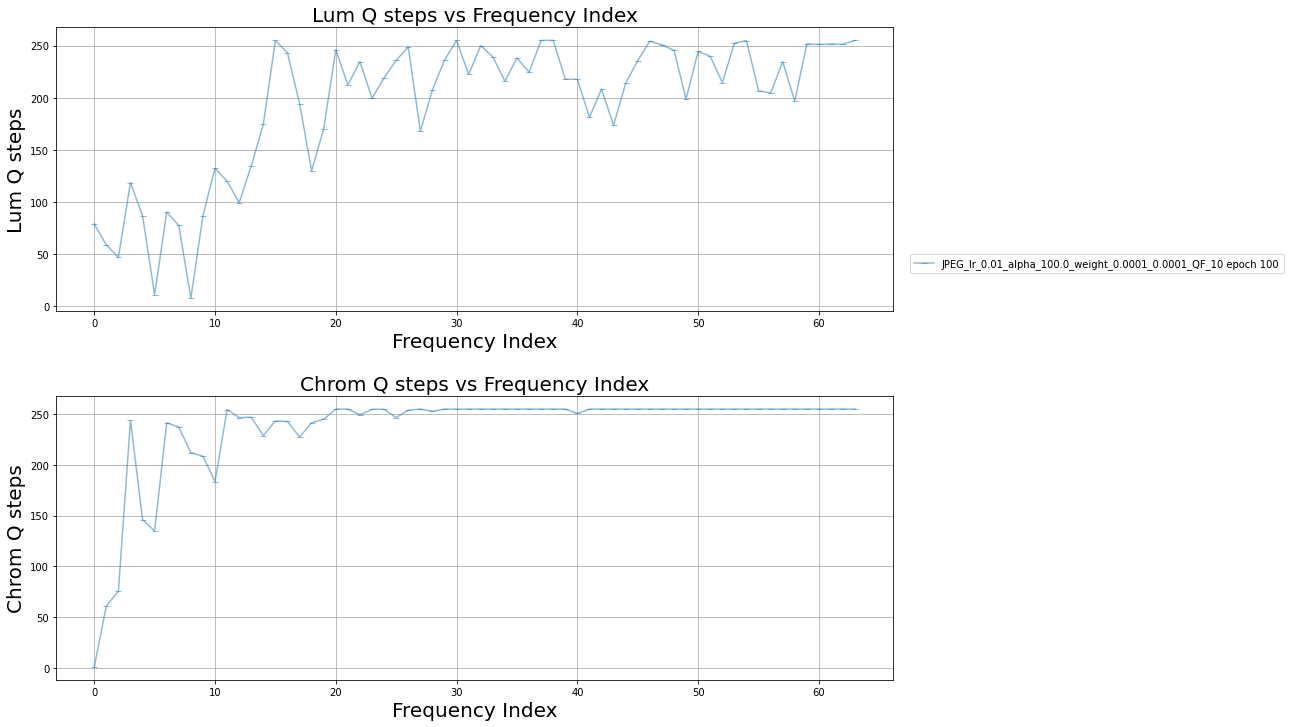

In [37]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 12))

q_path_0 = os.path.join(os.path.join(base_path, file_name_0), "trial_1/Q_tables")
q_path_1 = os.path.join(os.path.join(base_path, file_name_1), "trial_1/Q_tables")
q_path_2 = os.path.join(os.path.join(base_path, file_name_2), "trial_1/Q_tables")
q_path_3 = os.path.join(os.path.join(base_path, file_name_3), "trial_1/Q_tables")
q_path_4 = os.path.join(os.path.join(base_path, file_name_4), "trial_1/Q_tables")
q_path_5 = os.path.join(os.path.join(base_path, file_name_5), "trial_1/Q_tables")
q_path_6 = os.path.join(os.path.join(base_path, file_name_6), "trial_1/Q_tables")
q_path_7 = os.path.join(os.path.join(base_path, file_name_7), "trial_1/Q_tables")
q_path_8 = os.path.join(os.path.join(base_path, file_name_8), "trial_1/Q_tables")
q_path_9 = os.path.join(os.path.join(base_path, file_name_9), "trial_1/Q_tables")

# plot_q_table(q_path_0, marker_list[0], color_list[0], file_name_0,100)
# plot_q_table(q_path_1, marker_list[1], color_list[1], file_name_1)
# plot_q_table(q_path_2, marker_list[2], color_list[2], file_name_2)
# plot_q_table(q_path_3, marker_list[3], color_list[3], file_name_3)
# plot_q_table(q_path_4, marker_list[4], color_list[4], file_name_4)
# plot_q_table(q_path_5, marker_list[5], color_list[5], file_name_5)
# plot_q_table(q_path_6, marker_list[6], color_list[6], file_name_6)
plot_q_table(q_path_7, marker_list[7], color_list[7], file_name_7,100)
# plot_q_table(q_path_8, marker_list[8], color_list[8], file_name_8)
# plot_q_table(q_path_9, marker_list[9], color_list[9], file_name_9)

# plot_q_table_QF(96)

plt.subplots_adjust(hspace=0.3)
plt.legend(bbox_to_anchor=(1.02, 1.5), loc=2, borderaxespad=0)
plt.show()

# Plot Alpha tables

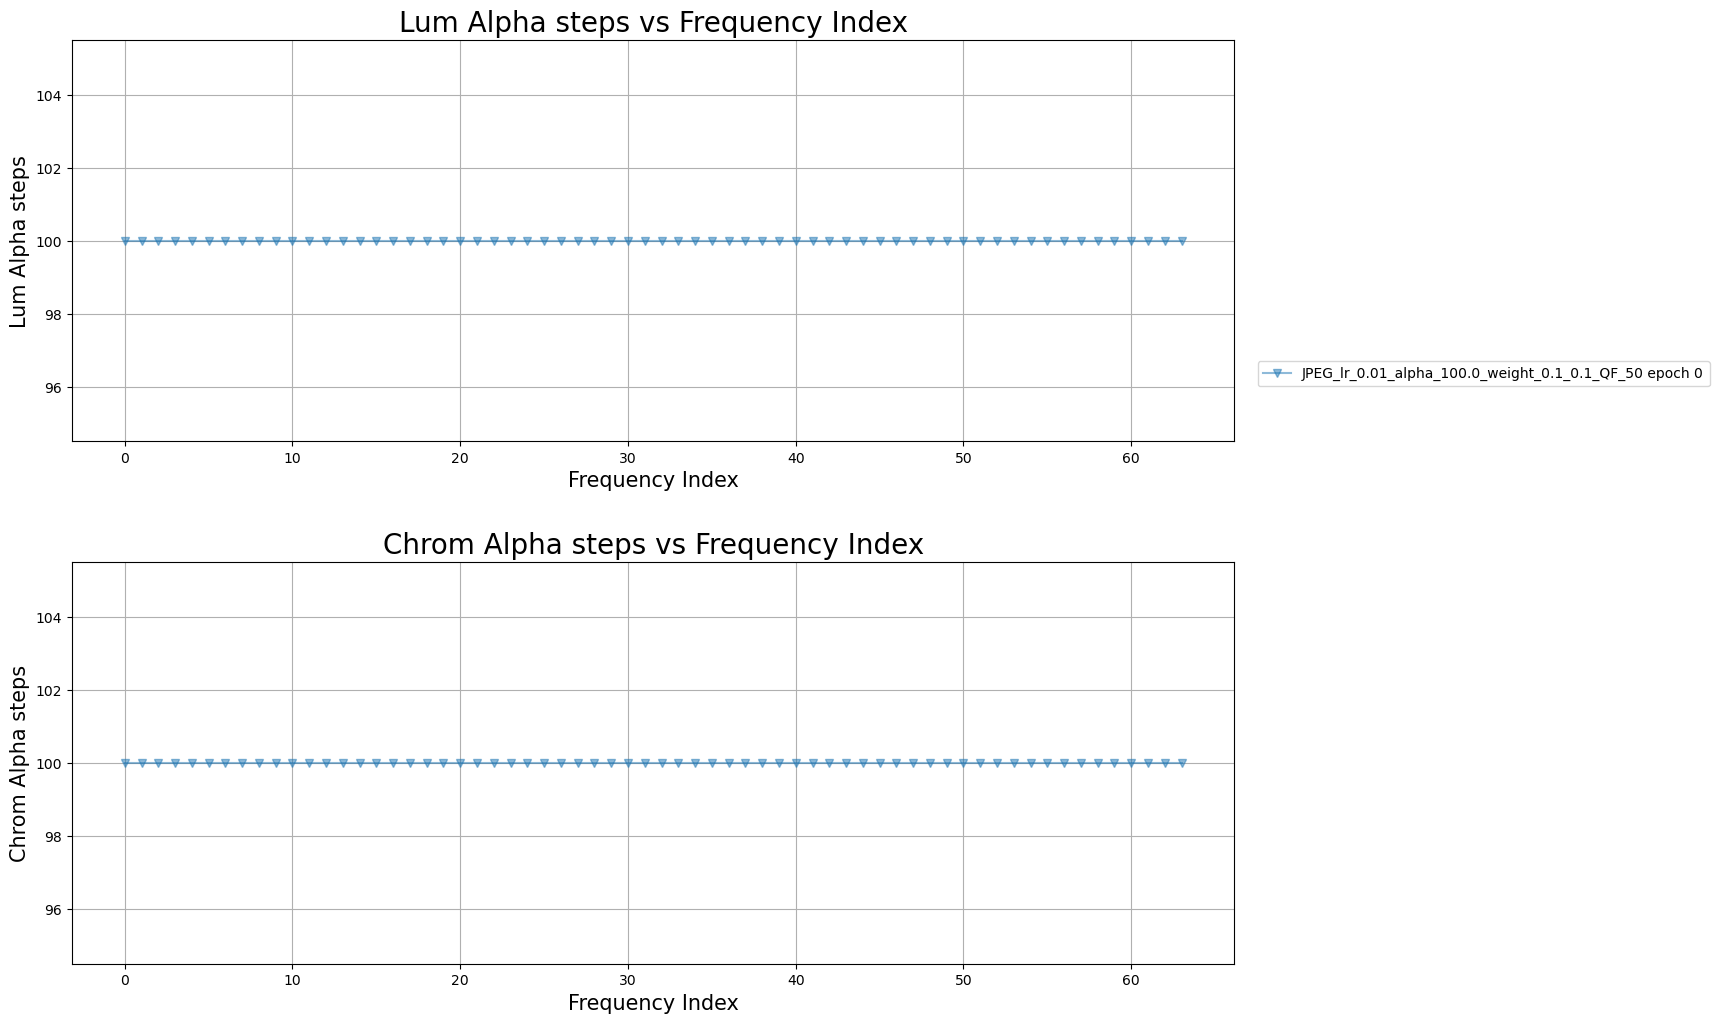

In [12]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 12))

alpha_path_0 = os.path.join(os.path.join(base_path, file_name_0), "trial_1/Alpha_tables")
alpha_path_1 = os.path.join(os.path.join(base_path, file_name_1), "trial_1/Alpha_tables")
alpha_path_2 = os.path.join(os.path.join(base_path, file_name_2), "trial_1/Alpha_tables")
alpha_path_3 = os.path.join(os.path.join(base_path, file_name_3), "trial_1/Alpha_tables")
alpha_path_4 = os.path.join(os.path.join(base_path, file_name_4), "trial_1/Alpha_tables")
alpha_path_5 = os.path.join(os.path.join(base_path, file_name_5), "trial_1/Alpha_tables")
alpha_path_6 = os.path.join(os.path.join(base_path, file_name_6), "trial_1/Alpha_tables")
alpha_path_7 = os.path.join(os.path.join(base_path, file_name_6), "trial_1/Alpha_tables")
alpha_path_8 = os.path.join(os.path.join(base_path, file_name_6), "trial_1/Alpha_tables")
alpha_path_9 = os.path.join(os.path.join(base_path, file_name_6), "trial_1/Alpha_tables")

# plot_alpha_table(alpha_path_1, marker_list[0], color_list[0], file_name_1)
# plot_alpha_table(alpha_path_2, marker_list[1], color_list[1], file_name_2)
# plot_alpha_table(alpha_path_3, marker_list[2], color_list[2], file_name_3)
plot_alpha_table(alpha_path_4, marker_list[3], color_list[3], file_name_4)
# plot_alpha_table(alpha_path_5, marker_list[4], color_list[4], file_name_5)
# plot_alpha_table(alpha_path_6, marker_list[5], color_list[5], file_name_6)
# plot_alpha_table(alpha_path_7, marker_list[6], color_list[6], file_name_7)
# plot_alpha_table(alpha_path_8, marker_list[7], color_list[7], file_name_8)
# plot_alpha_table(alpha_path_9, marker_list[8], color_list[8], file_name_9)

plt.subplots_adjust(hspace=0.3)
plt.legend(bbox_to_anchor=(1.02, 1.5), loc=2, borderaxespad=0)
plt.show()

# Plot HDQ baseline

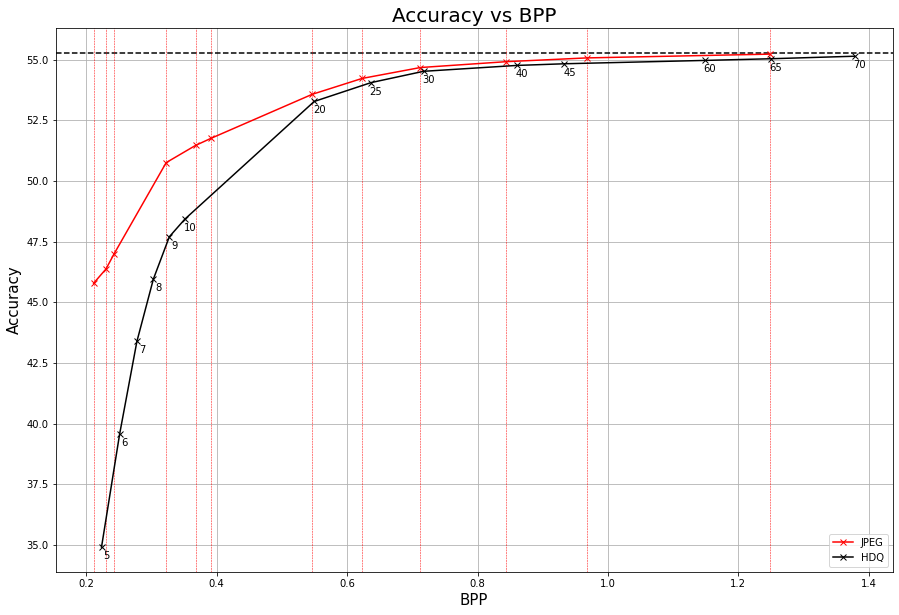

In [55]:
JPEG_x = [1.248896937864914, 0.968056524423821, 0.844145115782546, 0.712328337495558, 0.623033466873948, 
          0.546347268015753, 0.39126013760726, 0.367499542806759, 0.32251122587193, 0.242558152469831, 0.230178814534385, 0.211207192770502]
JPEG_y = [55.22954559326172, 55.074214935302734, 54.918880462646484, 54.67725372314453, 54.228511810302734, 
          53.572662353515625, 51.760440826416016, 51.46703338623047, 50.75940704345703, 46.99689483642578, 46.37556076049805, 45.78874588012695]


plt.figure(figsize=(15, 10))
plt.axhline(y=55.28, color='black', linestyle='--') # baseline

plt.plot(JPEG_x, JPEG_y, marker="x", label="JPEG", color="r")
for x in JPEG_x:
    plt.axvline(x=x, color='red', linestyle='--', linewidth=0.5)
plot_data_HDQ(base_path, 1, 70) # JPGE baseline

plt.xlabel('BPP', fontsize=15)
plt.ylabel('Accuracy', fontsize=15)
plt.title('Accuracy vs BPP', fontsize=20)
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# Plot the images

In [6]:
import os
import tkinter as tk
from tkinter import Button, Tk, Frame, font
from matplotlib.figure import Figure
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg


colors_list = ['red', 'green', 'blue', 'cyan', 'magenta', 'yellow', 'black', 'orange', 'purple', 'brown']
marker_list = ['o','^','.','v','>','v','|','_',',','x']
color_marker_index = 0
plot_references = {}
button_references = {}

def read_file(file_path):
    data = []
    with open(file_path, 'r') as file:
        next(file)  # 忽略第一行
        for line in file:
            parts = line.split()
            row = list(map(float, parts))
            data.append(row)
    return data


def get_greedy_BPP(x_values, y_values):
    """Select points based on greedy algorithm focusing on better y values with less or equal x values."""
    # Sort data by y_values while maintaining correspondence with x_values and their original indices
    sorted_pairs = sorted(zip(y_values, x_values, range(len(y_values))), key=lambda x: x[0], reverse=True)
    sorted_y_values, sorted_x_values, sorted_indices = zip(*sorted_pairs)

    # Initialize with the best found values (highest y)
    best_y = sorted_y_values[0]
    best_x = sorted_x_values[0]
    # print(f"Best accuracy: {best_y:.8f} at epoch: {sorted_indices[0]+1} with BPP: {best_x:.8f}")
    
    new_y, new_x, new_indices = [], [], []
    for idx, (x_val, y_val) in enumerate(zip(sorted_x_values, sorted_y_values)):
        # Update best seen values and collect if current point is better or equal
        if x_val <= best_x and y_val <= best_y:
            best_x, best_y = x_val, y_val
            new_x.append(x_val)
            new_y.append(y_val)
            new_indices.append(sorted_indices[idx])

    return new_x, new_y, new_indices


def toggle_plot(fig, ax, canvas, file_path, button, marker='o', label='Data', greedy=True):
    global color_marker_index, plot_references

    # HDQ data and quality factor labels
    HDQ_x = [8.716203977990077, 7.228310027696940, 5.72461501098230, 4.952189957062705, 3.806416170881829, 2.776283525221094, 2.624794523274442, 1.378255916045047, 1.148885369591459, 0.859938243904894, 0.717285850805108, 0.549537309478553, 0.351107887058298]
    HDQ_y = [55.298583984375000, 55.246807098388672, 55.281326293945312, 55.281326293945312, 55.229545593261719, 55.195030212402344, 55.195030212402344, 55.143249511718750, 54.970657348632812, 54.763549804687500, 54.521919250488281, 53.279254913330078, 48.429409027099609]
    QF_ls = [100,99,98,97,95,91,90,70,60,40,30,20,10]

    # Always plot the HDQ data
    ax.plot(HDQ_x, HDQ_y, marker="x", color="gray")
    for i, (x, y) in enumerate(zip(HDQ_x, HDQ_y)):
        ax.annotate(str(QF_ls[i]), (x, y), textcoords="offset points", xytext=(0,10), ha='center')

    # Plot the horizontal line for the underlying model
    ax.axhline(y=55.28, color='black', linestyle='--')
    
    # Toggle off if already plotted
    if file_path in plot_references:
        for item in plot_references[file_path]:
            item.remove()
        del plot_references[file_path]
        button.config(relief="raised")
        ax.legend(loc="lower right")
        canvas.draw()
        return

    # Plot the data
    data = read_file(file_path)
    y_values = [row[2] for row in data]
    x_values = [row[6] for row in data]
    current_color = colors_list[color_marker_index % len(colors_list)]
    current_marker = marker_list[color_marker_index % len(marker_list)]
    color_marker_index += 1

    plot_items = []
    
    if greedy:
        new_x_values, new_y_values, new_indices = get_greedy_BPP(x_values, y_values)
        line1 = ax.plot(x_values, y_values, marker=current_marker, color=current_color, alpha=0.2, linestyle="")
        line2 = ax.plot(new_x_values, new_y_values, marker=current_marker, label=label, color=current_color, alpha=1)
        plot_items.extend(line1)
        plot_items.extend(line2)
        # for i, (x, y) in enumerate(zip(new_x_values, new_y_values)):
        #     annotation = ax.annotate(str(new_indices[i]+1), (x, y), textcoords="offset points", xytext=(0,10), ha='center')
        #     plot_items.append(annotation)
    else:
        line = ax.plot(x_values, y_values, marker=current_marker, label=label, color=current_color, alpha=0.9)
        plot_items.append(line)

    plot_references[file_path] = plot_items
    button.config(relief="sunken")  # Change the button appearance to indicate it's active
    ax.legend(loc="lower right")
    canvas.draw()


def create_gallery(base_path):
    root = Tk()
    root.title("Data Gallery")
    # root.attributes('-fullscreen', True)
    root.state('zoomed')
    
    fig = Figure(figsize=(10, 6))
    ax = fig.add_subplot(111)

    canvas = FigureCanvasTkAgg(fig, master=root)
    canvas_widget = canvas.get_tk_widget()
    canvas_widget.pack(side=tk.TOP, fill=tk.BOTH, expand=True)

    button_frame = Frame(root)
    button_frame.pack(side=tk.BOTTOM, fill=tk.X)

    # directories = [d for d in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, d))]
    directories = [d for d in os.listdir(base_path) if (os.path.isdir(os.path.join(base_path, d)) and 'hardness' in d) ]
    print(directories)
    row, col = 0, 0
    custom_font = font.Font(family="Helvetica", size=7, weight="bold")
    for dir_name in directories:
        file_path = os.path.join(base_path, dir_name, "trial_1", "logs.txt")
        button = Button(button_frame, text=dir_name, relief="raised", font=custom_font)
        button.grid(row=row, column=col, sticky="ew")
        button.config(command=lambda b=button, f=file_path, l=dir_name: toggle_plot(fig, ax, canvas, f, b, label=l))
        col += 1
        if col % 6 == 0:
            row += 1
            col = 0

    root.mainloop()


base_path = './save/CUB200/resnet18'
create_gallery(base_path)

['JPEG_lr_0.005_alpha_100.0_weight_0.01_0.01', 'JPEG_lr_0.005_alpha_100.0_weight_0.1_0.1', 'JPEG_lr_0.005_alpha_100.0_weight_0.5_0.5', 'JPEG_lr_0.005_alpha_100.0_weight_1.0_1.0', 'JPEG_lr_0.005_alpha_100.0_weight_5.0_5.0', 'JPEG_lr_0.015_alpha_10.0_weight_0.005_0.005', 'JPEG_lr_0.01_weight_0.001_0.001_hardness_20.0', 'JPEG_lr_0.01_weight_0.1_0.1_hardness_20.0', 'JPEG_lr_0.01_weight_2.0_2.0_hardness_20.0', 'JPEG_lr_0.01_weight_5.0_5.0_hardness_20.0', 'JPEG_lr_0.025_alpha_10.0_weight_0.005_0.005', 'JPEG_lr_0.025_weight_0.005_0.005_hardness_10.0', 'JPEG_lr_0.025_weight_0.005_0.005_hardness_20.0', 'JPEG_lr_0.025_weight_0.005_0.005_hardness_3.0', 'JPEG_lr_0.025_weight_0.005_0.005_hardness_40.0', 'JPEG_lr_0.02_alpha_10.0_weight_0.005_0.005', 'JPEG_lr_0.02_alpha_10.0_weight_0.01_0.01', 'JPEG_lr_0.02_alpha_10.0_weight_0.02_0.02', 'JPEG_lr_0.02_weight_0.001_0.001_hardness_20.0', 'JPEG_lr_0.02_weight_0.005_0.005_hardness_20.0', 'JPEG_lr_0.02_weight_0.1_0.1_hardness_20.0', 'JPEG_lr_0.02_weight_2.

# Calculate Pearson correlation

Pearson correlation coefficient: 0.9960238459466372
P-value: 8.636814268122981e-106


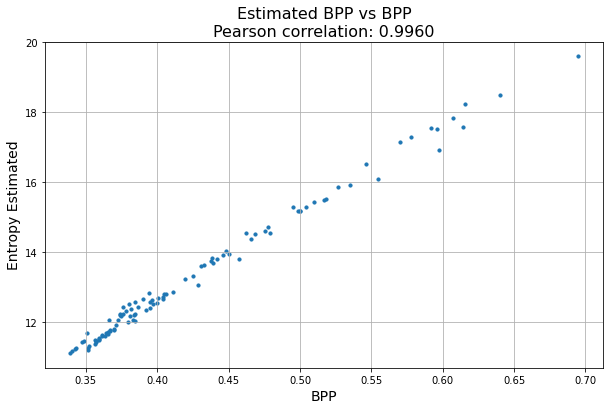

In [64]:
import numpy as np
from scipy.stats import pearsonr

file_name_1 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(0.01, 100.0, 0.0001, 0.0001, 10)

data = read_file(os.path.join(os.path.join(base_path, file_name_1), "trial_1/logs.txt"))
CEloss = [(row[7] + row[8] + row[9] + row[10]) for row in data] # entropy
bpp = [(row[6]) for row in data] # test bpp

correlation, p_value = pearsonr(CEloss, bpp)
print(f"Pearson correlation coefficient: {correlation}")
print(f"P-value: {p_value}")

plt.figure(figsize=(10, 6))
plt.scatter(bpp, CEloss, s=10)
plt.title(f'Estimated BPP vs BPP\nPearson correlation: {correlation:.4f}', fontsize=16)
plt.xlabel('BPP', fontsize=14)
plt.ylabel('Entropy Estimated', fontsize=14)
plt.grid(True)
plt.show()

method 1
Pearson correlation coefficient: 0.9779139547429193
P-value: 0.0


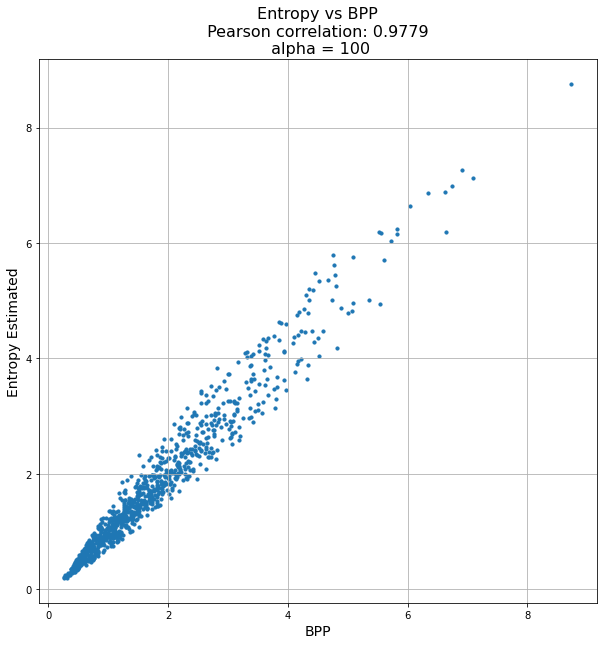

In [92]:
data = read_file("./save/CUB200/resnet18/BPP_Entropy_comparision_1_alpha_100.txt")
# data = data[:500]
CEloss = [(row[1]/22) for row in data] # entropy
bpp = [(row[0]) for row in data] # test bpp

correlation, p_value = pearsonr(CEloss, bpp)
print("method 1")
print(f"Pearson correlation coefficient: {correlation}")
print(f"P-value: {p_value}")

plt.figure(figsize=(10, 10))
plt.scatter(bpp, CEloss, s=10)
plt.title(f'Entropy vs BPP\n Pearson correlation: {correlation:.4f} \n alpha = 100', fontsize=16)
plt.xlabel('BPP', fontsize=14)
plt.ylabel('Entropy Estimated', fontsize=14)
plt.grid(True)
plt.show()

In [8]:
import torch
file_path = './save/imagenet/resnet18/JPEG_lr_0.01_alpha_100.0_weight_0.1_0.1_QF_40/trial_1/Q_tables/q_table_epoch_7.pt'
data = torch.load(file_path)
print(data.shape)

torch.Size([2, 8, 8])
